# Project 1 — Wholesale Customer Segmentation
**DSC8307 | Advent 2026 | Access No. B34982**

## Problem formulation and study design
Identify interpretable spending-based segments among 440 wholesale customers and recommend differentiated service strategies. Six monetary spending variables form the clustering feature space; `Channel` (1 Horeca, 2 Retail) and `Region` (1 Lisbon, 2 Oporto, 3 Other) are **external descriptors only**, not model inputs. Annual spending is in unspecified monetary units (m.u.). Source: supplied wholesale dataset README and DSC8307 assignment, pp. 1–3.

**Design:** audit → exploratory analysis → compare raw-standardized and log1p-standardized representations → Hopkins cluster tendency → tune K-means, Ward and DBSCAN → evaluate validity, size and stability → choose a defensible solution → profile in original spending units. No known ground-truth segments exist; internal scores do not establish business utility.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from IPython.display import display, Markdown
SEED=34982
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
DATA=Path(".")
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import skew
from sklearn.utils import resample
spend=['Fresh','Milk','Grocery','Frozen','Detergents_Paper','Delicatessen']
df=pd.read_csv(DATA/'wholesale-customers.csv')
assert len(df)==440 and set(spend+['Channel','Region']).issubset(df.columns)
display(df.head(),df.info(),df.describe(include='all').T)
print('Missing:',df.isna().sum().to_dict(),'Exact duplicates:',df.duplicated().sum())
print('Channel counts:',df.Channel.value_counts().to_dict(),'Region counts:',df.Region.value_counts().to_dict())
assert (df[spend]>=0).all().all(), 'Nonnegative spending required for log1p'


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicatessen      440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


None

,count,mean,std,min,25%,50%,75%,max
Channel,440.0,1.322727,0.468052,1.0,1.00,1.0,2.00,2.0
Region,440.0,2.543182,0.774272,1.0,2.00,3.0,3.00,3.0
Fresh,440.0,12000.297727,12647.328865,3.0,3127.75,8504.0,16933.75,112151.0
Milk,440.0,5796.265909,7380.377175,55.0,1533.00,3627.0,7190.25,73498.0
Grocery,440.0,7951.277273,9503.162829,3.0,2153.00,4755.5,10655.75,92780.0
Frozen,440.0,3071.931818,4854.673333,25.0,742.25,1526.0,3554.25,60869.0
Detergents_Paper,440.0,2881.493182,4767.854448,3.0,256.75,816.5,3922.00,40827.0
Delicatessen,440.0,1524.870455,2820.105937,3.0,408.25,965.5,1820.25,47943.0


Missing: {'Channel': 0, 'Region': 0, 'Fresh': 0, 'Milk': 0, 'Grocery': 0, 'Frozen': 0, 'Detergents_Paper': 0, 'Delicatessen': 0} Exact duplicates: 0
Channel counts: {1: 298, 2: 142} Region counts: {3: 316, 1: 77, 2: 47}


## Exploratory diagnostics and preparation
Highly right-skewed expenditures and large values can dominate Euclidean distances. We retain legitimate high-spend customers (not automatically erroneous), transform spending using `log1p`, then standardize features; compare with standardizing untransformed spending. No rows are removed for being duplicates without evidence of erroneous records. Missing values, if any, must be reviewed rather than silently imputed.

,skew,zero_pct,IQR_upper_outliers
Fresh,2.561323,0.0,20
Milk,4.053755,0.0,28
Grocery,3.587429,0.0,24
Frozen,5.907986,0.0,43
Detergents_Paper,3.631851,0.0,30
Delicatessen,11.151586,0.0,27


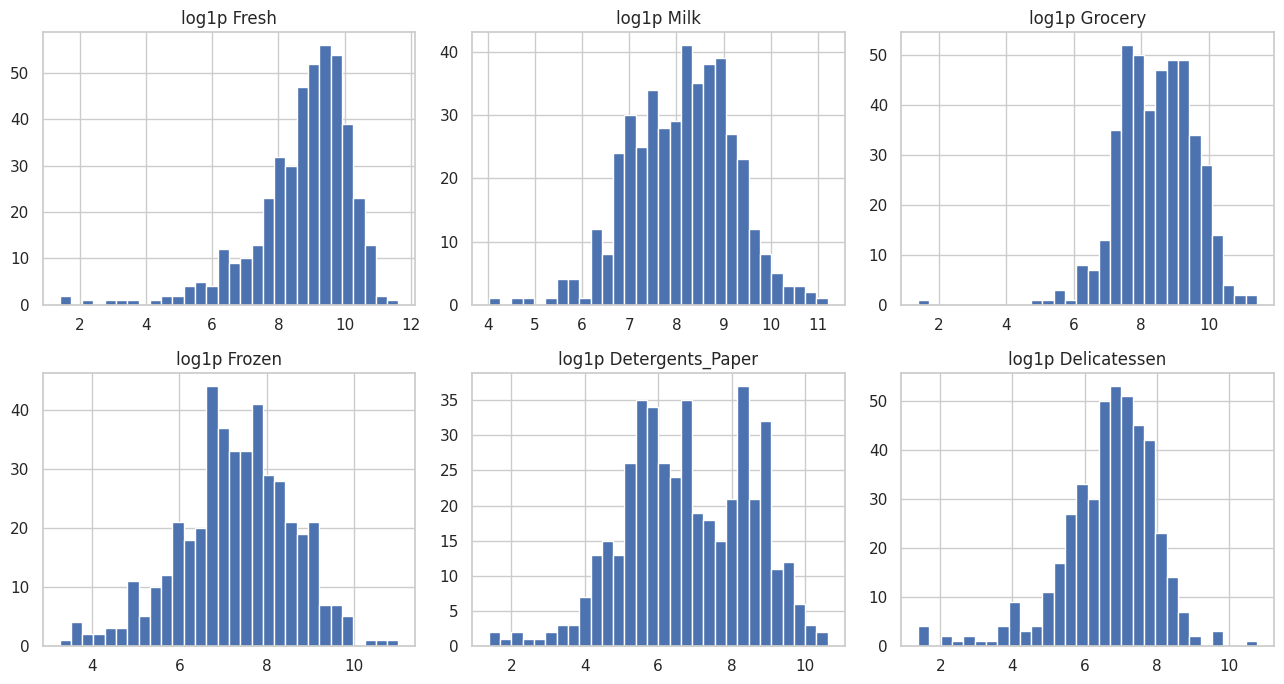

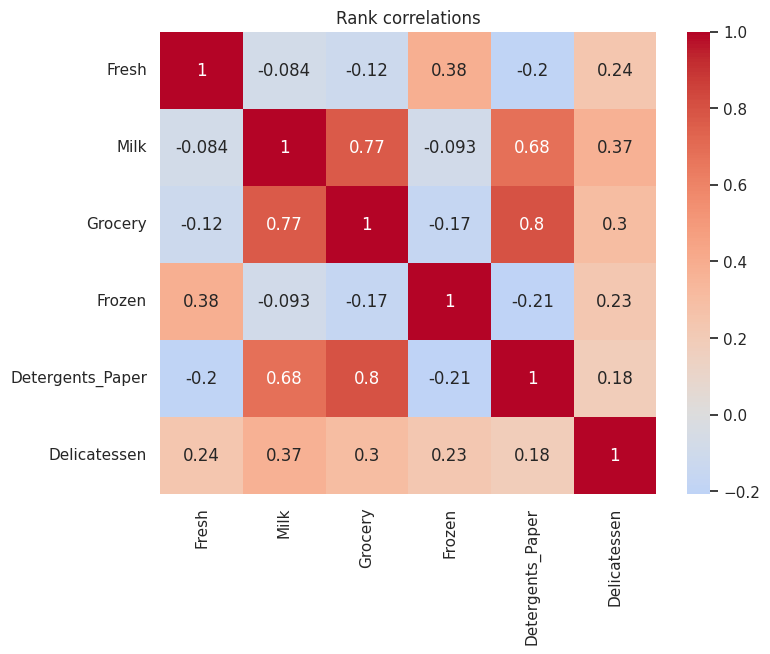

In [2]:
display(pd.DataFrame({'skew':df[spend].skew(),'zero_pct':(df[spend]==0).mean()*100,'IQR_upper_outliers':[(df[c]>(df[c].quantile(.75)+1.5*(df[c].quantile(.75)-df[c].quantile(.25)))).sum() for c in spend]},index=spend))
fig,ax=plt.subplots(2,3,figsize=(13,7));
for a,c in zip(ax.flat,spend):a.hist(np.log1p(df[c]),bins=30);a.set_title('log1p '+c)
plt.tight_layout();plt.show()
plt.figure(figsize=(8,6));sns.heatmap(df[spend].corr(method='spearman'),annot=True,cmap='coolwarm',center=0);plt.title('Rank correlations');plt.show()
assert not df[spend].isna().any().any(), 'Resolve missing values before clustering'
Xlog=StandardScaler().fit_transform(np.log1p(df[spend]));Xraw=StandardScaler().fit_transform(df[spend]);


## Cluster tendency
Hopkins H approaches 0.5 for a uniform reference distribution, and higher values suggest aggregation. The reference is uniform within the observed standardized feature bounding box; it is sensitive to high-dimensional geometry and should not be interpreted as a formal significance test. Repeat over seeds to examine stability.

In [3]:
def hopkins(X,seed,m=80):
 rng=np.random.default_rng(seed);m=min(m,len(X)-1)
 ids=rng.choice(len(X),size=m,replace=False)
 u=rng.uniform(X.min(axis=0),X.max(axis=0),size=(m,X.shape[1]))
 nn=NearestNeighbors(n_neighbors=2).fit(X)
 wd=nn.kneighbors(X[ids])[0][:,1]
 ud=nn.kneighbors(u,n_neighbors=1)[0][:,0]
 return float(ud.sum()/(ud.sum()+wd.sum()))
hs=[hopkins(Xlog,SEED+i) for i in range(15)]
print('Hopkins mean / SD / range:',np.mean(hs),np.std(hs),min(hs),max(hs))


Hopkins mean / SD / range: 0.7999189412275606 0.012956271327376428 0.7742986339677271 0.8244103202882009


## Model comparison and tuning
K-means minimizes within-cluster squared Euclidean distances, Ward agglomeration minimizes incremental within-cluster variance, and DBSCAN discovers density-connected groups while allowing noise. Compare both feature representations, 2–7 groups for partitioning/hierarchical, and multiple density neighborhoods. Silhouette, Davies–Bouldin and Calinski–Harabasz are undefined for a single cluster or all unique labels; DBSCAN metrics below exclude noise but record noise fraction, preventing favorable metrics for tiny retained subsets.

In [4]:
def quality(X,lab):
 lab=np.asarray(lab);ok=lab!=-1;valid=np.unique(lab[ok]);noise=1-ok.mean();counts=pd.Series(lab[ok]).value_counts()
 out={'clusters':len(valid),'noise_pct':100*noise,'min_cluster':int(counts.min()) if len(counts) else 0,'silhouette':np.nan,'DB':np.nan,'CH':np.nan}
 if 2<=len(valid)<ok.sum() and ok.sum()>=30 and noise<.5 and out['min_cluster']>=5:
  out.update(silhouette=float(silhouette_score(X[ok],lab[ok])),DB=float(davies_bouldin_score(X[ok],lab[ok])),CH=float(calinski_harabasz_score(X[ok],lab[ok])))
 return out
rows=[];fits={}
for representation,X in [('log_scaled',Xlog),('raw_scaled',Xraw)]:
 for k in range(2,8):
  for method,model in [('KMeans',KMeans(n_clusters=k,n_init=15,random_state=SEED)),('Ward',AgglomerativeClustering(n_clusters=k,linkage='ward'))]:
   lab=model.fit_predict(X);key=(representation,method,str(k));fits[key]=lab
   rows.append(dict(representation=representation,method=method,parameter=str(k),**quality(X,lab)))
 for eps in [.5,.75,1,1.25,1.5,1.75,2,2.5,3]:
  for ms in [5,10,15]:
   lab=DBSCAN(eps=eps,min_samples=ms).fit_predict(X);key=(representation,'DBSCAN',f'{eps}/{ms}');fits[key]=lab
   rows.append(dict(representation=representation,method='DBSCAN',parameter=f'{eps}/{ms}',**quality(X,lab)))
results=pd.DataFrame(rows);display(results.sort_values('silhouette',ascending=False).head(20))
display(results.groupby(['representation','method']).agg({'silhouette':'max','noise_pct':'median','clusters':'median'}))


,representation,method,parameter,clusters,noise_pct,min_cluster,silhouette,DB,CH
40,raw_scaled,Ward,2,2,0.000000,6,0.792457,0.908645,105.441815
39,raw_scaled,KMeans,2,2,0.000000,36,0.613694,1.133011,153.574617
51,raw_scaled,DBSCAN,0.5/5,2,39.545455,5,0.520979,0.473275,36.169063
41,raw_scaled,KMeans,3,3,0.000000,13,0.333917,1.178088,137.584453
0,log_scaled,KMeans,2,2,0.000000,188,0.290328,1.351502,189.049797
42,raw_scaled,Ward,3,3,0.000000,6,0.264609,1.284521,111.151039
2,log_scaled,KMeans,3,3,0.000000,83,0.258507,1.352874,152.844619
1,log_scaled,Ward,2,2,0.000000,178,0.258495,1.600363,134.624461
3,log_scaled,Ward,3,3,0.000000,53,0.254657,1.538995,116.799278
7,log_scaled,Ward,5,5,0.000000,18,0.202547,1.386198,100.014606


silhouette  noise_pct  clusters
representation method                                 
log_scaled     DBSCAN         NaN  10.909091       1.0
               KMeans    0.290328   0.000000       4.5
               Ward      0.258495   0.000000       4.5
raw_scaled     DBSCAN    0.520979   6.590909       1.0
               KMeans    0.613694   0.000000       4.5
               Ward      0.792457   0.000000       4.5

## Robustness, selection and interpretability
We select the highest silhouette **among log-transformed solutions** with at least two groups, no more than 20% noise, and at least 10 customers per cluster. This is an explicit heuristic, not an optimality theorem; we inspect business interpretability and compare method alternatives. Stability is assessed by adjusted Rand index under 80% customer subsampling for all three methods. Feature perturbation can expose sensitivity but is not a substitute for new customer samples.

In [5]:
eligible=results[(results.representation=='log_scaled')&(results.clusters.between(2,7))&(results.noise_pct<=20)&(results.min_cluster>=10)&results.silhouette.notna()].copy()
assert len(eligible), 'No valid solutions: revisit parameters'
chosen=eligible.sort_values('silhouette',ascending=False).iloc[0];key=(chosen.representation,chosen.method,chosen.parameter);labels=fits[key]
print('Selected:',chosen.to_dict())
# Compare repeatability for KMeans; Ward and DBSCAN use 80% subsample agreement on overlapping rows.
for method in ['KMeans','Ward','DBSCAN']:
 cand=eligible[eligible.method==method].sort_values('silhouette',ascending=False)
 if cand.empty:continue
 r=cand.iloc[0];original=fits[(r.representation,r.method,r.parameter)];scores=[]
 for i in range(8):
  idx=np.sort(np.random.default_rng(SEED+i).choice(len(Xlog),size=int(.8*len(Xlog)),replace=False))
  if method=='KMeans':model=KMeans(n_clusters=int(r.parameter),n_init=10,random_state=SEED+i)
  elif method=='Ward':model=AgglomerativeClustering(n_clusters=int(r.parameter),linkage='ward')
  else:
   eps,ms=r.parameter.split('/');model=DBSCAN(eps=float(eps),min_samples=int(ms))
  pred=model.fit_predict(Xlog[idx]);scores.append(adjusted_rand_score(original[idx],pred))
 print(method,'subsample ARI mean (SD):',round(np.mean(scores),3),round(np.std(scores),3))


Selected: {'representation': 'log_scaled', 'method': 'KMeans', 'parameter': '2', 'clusters': 2, 'noise_pct': 0.0, 'min_cluster': 188, 'silhouette': 0.2903284869973543, 'DB': 1.351501586224928, 'CH': 189.04979701772055}
KMeans subsample ARI mean (SD): 0.976 0.026
Ward subsample ARI mean (SD): 0.454 0.181


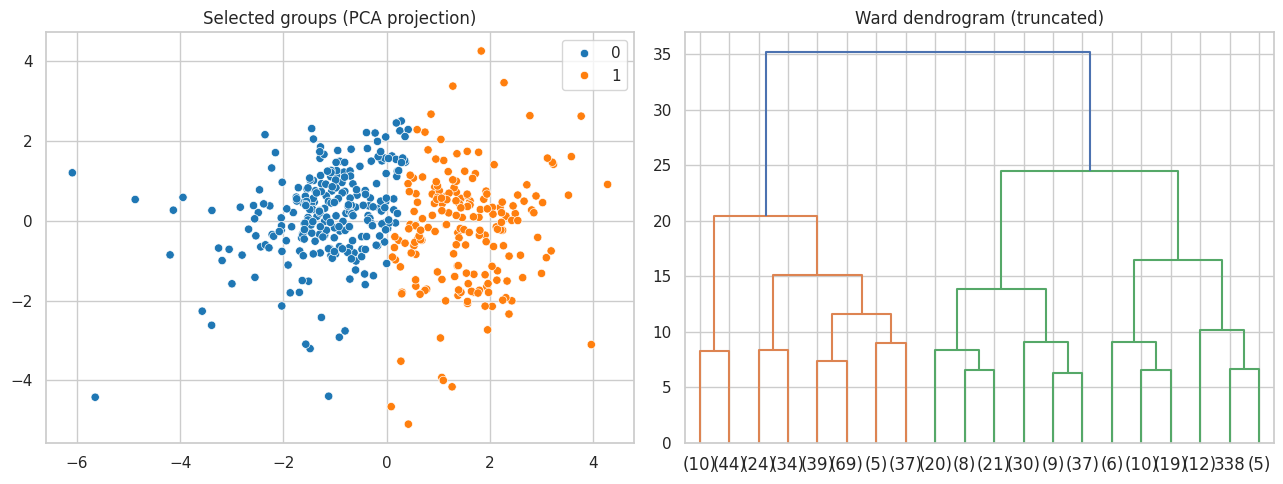

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen,n
cluster,,,,,,,
0,10347.5,1871.0,2406.0,2225.0,327.5,749.5,252
1,5406.5,7690.5,11527.0,1061.5,4495.0,1388.5,188


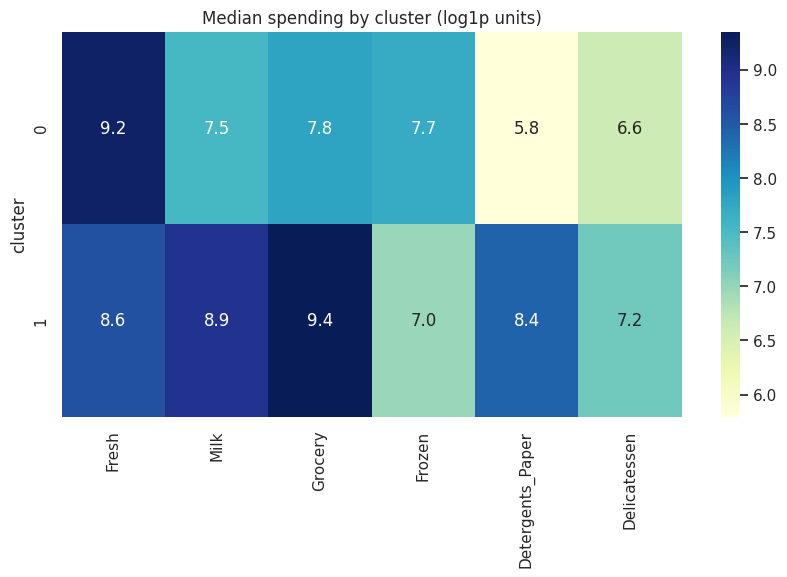

Channel distribution within clusters (%)


Channel,1,2
row_0,,
0,96.8,3.2
1,28.7,71.3


Region distribution within clusters (%)


Region,1,2,3
row_0,,,
0,19.0,11.1,69.8
1,15.4,10.1,74.5


In [6]:
fig,ax=plt.subplots(1,2,figsize=(13,5))
coords=PCA(n_components=2,random_state=SEED).fit_transform(Xlog)
sns.scatterplot(x=coords[:,0],y=coords[:,1],hue=labels,palette='tab10',ax=ax[0],legend='full');ax[0].set_title('Selected groups (PCA projection)')
z=linkage(Xlog,method='ward');dendrogram(z,truncate_mode='lastp',p=20,ax=ax[1]);ax[1].set_title('Ward dendrogram (truncated)');plt.tight_layout();plt.show()
profiles=df.assign(cluster=labels).groupby('cluster')[spend].median();sizes=pd.Series(labels).value_counts().sort_index();display(profiles.assign(n=sizes))
fig,ax=plt.subplots(figsize=(10,5));sns.heatmap(np.log1p(profiles),annot=True,fmt='.1f',cmap='YlGnBu',ax=ax);ax.set_title('Median spending by cluster (log1p units)');plt.show()
print('Channel distribution within clusters (%)');display(pd.crosstab(labels,df.Channel,normalize='index').mul(100).round(1))
print('Region distribution within clusters (%)');display(pd.crosstab(labels,df.Region,normalize='index').mul(100).round(1))


## Cross-method diagnostics and sensitivity
The tables below compare the strongest **eligible** candidate from each method on the same log-scaled feature space. DBSCAN noise is reported separately because its silhouette excludes noise points. A simple perturbation check also examines whether changing the representation changes the K-Means partition. Neither metric proves stable commercial segments.

,method,parameter,clusters,noise_pct,min_cluster,silhouette,DB,CH
0,KMeans,2,2,0.0,188,0.290,1.352,189.050
1,Ward,2,2,0.0,178,0.258,1.600,134.624


Two-cluster representation sensitivity (adjusted Rand index): 0.081


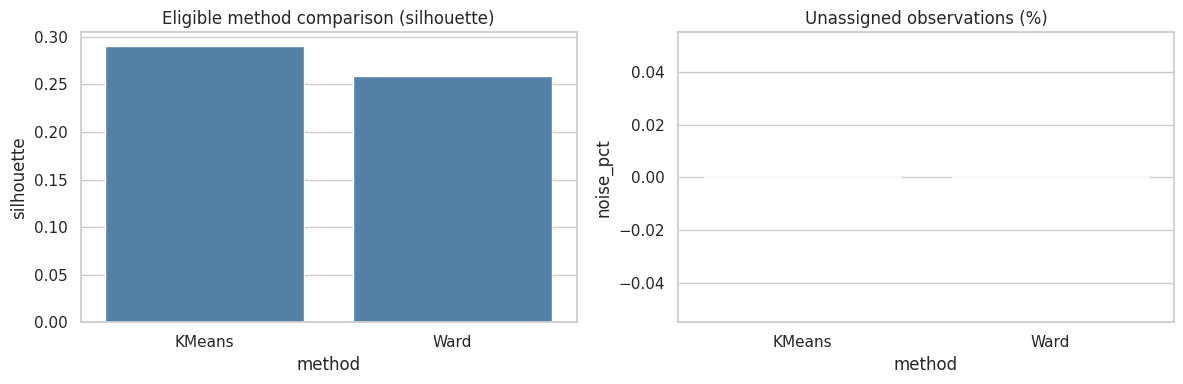

In [7]:
comparison=(eligible.sort_values('silhouette',ascending=False).groupby('method',as_index=False).first()[['method','parameter','clusters','noise_pct','min_cluster','silhouette','DB','CH']]);display(comparison.round(3))
raw_best=results[(results.representation=='raw_scaled')&(results.method=='KMeans')&(results.clusters==2)].iloc[0]
log_two=fits[('log_scaled','KMeans','2')];raw_two=fits[('raw_scaled','KMeans','2')]
print('Two-cluster representation sensitivity (adjusted Rand index):',round(adjusted_rand_score(log_two,raw_two),3))
fig,axes=plt.subplots(1,2,figsize=(12,4))
sns.barplot(data=comparison,x='method',y='silhouette',color='steelblue',ax=axes[0]);axes[0].set_title('Eligible method comparison (silhouette)')
sns.barplot(data=comparison,x='method',y='noise_pct',color='steelblue',ax=axes[1]);axes[1].set_title('Unassigned observations (%)')
plt.tight_layout();plt.show()

## Segment naming and differentiated service recommendations
Names below are **data-driven heuristics** derived from the highest relative median category spend; validate with sales teams before operational use. `-1` represents density-model noise and is not a coherent customer segment. The median profiles, category ratios and Channel/Region tables above are the empirical basis for interpretation.

In [8]:
global_median=df[spend].median().replace(0,1)
for cluster,row in profiles.iterrows():
 if cluster==-1: name='Unassigned / density outliers';rec='Review individually; avoid automated discount or exclusion.'
 else:
  ratios=row/global_median;lead=ratios.sort_values(ascending=False).index[:2].tolist()
  name=' & '.join(lead)+'-oriented buyers'
  rec=('Tailor assortment, inventory forecasts and bundle offers to '+', '.join(lead)+'. '
       'Validate margins, purchase frequency and service needs before launching promotions.')
 print(f'Cluster {cluster}: {name}; n={sizes.loc[cluster]}; median spend total={row.sum():,.0f} m.u.\n  Recommendation: {rec}')


Cluster 0: Frozen & Fresh-oriented buyers; n=252; median spend total=17,926 m.u.
  Recommendation: Tailor assortment, inventory forecasts and bundle offers to Frozen, Fresh. Validate margins, purchase frequency and service needs before launching promotions.
Cluster 1: Detergents_Paper & Grocery-oriented buyers; n=188; median spend total=31,569 m.u.
  Recommendation: Tailor assortment, inventory forecasts and bundle offers to Detergents_Paper, Grocery. Validate margins, purchase frequency and service needs before launching promotions.


## Interpretation of observed results
The printed cluster sizes, category medians and channel/region cross-tabs above constitute the evidence for the descriptive names. The highest silhouette should not be confused with external validity: the 440-customer sample is small, clusters can overlap, and the observed segmentation may change under different distance metrics or incoming customers. The strongest eligible solution is compared against Ward and DBSCAN, including noise fractions and subsample agreement. For business application, test category-specific assortments, replenishment schedules and promotions in a pilot before scaling; evaluate realized margins, fulfillment rates and retention rather than treating cluster identity as a guarantee of value.

**Measured preprocessing sensitivity:** the two-cluster K-Means labels under raw-standardized versus log1p-standardized spending have adjusted Rand index **0.081**, demonstrating that customer assignments depend strongly on transformation. Therefore the selected segments are exploratory, not an invariant customer taxonomy. The log1p choice remains defensible for skewed spending, but alternative preprocessing should be tested before deployment.

## Critical interpretation, limitations and responsible application
- Internal metrics favor compact separation, not necessarily commercially meaningful segments; inspect alternative partitions, outlier sensitivity, and stability before rollout.
- Channel and Region were withheld from clustering, so cross-tabs describe association, **not** causal effects or validation labels.
- Annual spending does not measure margin, recency, product availability, customer satisfaction or lifetime value; no personalized credit or discriminatory treatment should be inferred.
- The source lacks time-series data and external ground truth. Pilot interventions with randomized or matched comparisons and monitor segment drift.

## References
1. Uganda Christian University. *DSC8307 Advent 2026 Assignment 2* (supplied PDF).
2. UCI Machine Learning Repository. *Wholesale customers* dataset (supplied CSV and README).
3. Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics*, 20, 53–65.
4. Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. *KDD*, 226–231.
5. Jain, A. K. (2010). Data clustering: 50 years beyond K-means. *Pattern Recognition Letters*, 31(8), 651–666.


## Extended robustness audit: resampling, alternative scaling and segment uncertainty

The following analysis tests whether conclusions survive alternative robust scaling and 80% bootstrap-like subsampling. **ARI** compares partitions on the same customers and is invariant to arbitrary cluster labels. A low ARI means that *membership* changes, even if the segment narratives appear plausible. The comparison does not establish an objectively true number of segments. Because the same data guide selection and assessment, internal validation scores are descriptive, not independent predictive validation.

,representation,ARI_vs_log_standard,silhouette,smallest_segment
0,log + standard,1.000,0.290,188
1,log + robust,0.928,0.253,188
2,raw + standard,0.081,0.614,36


log + standard 80% subsample ARI median [10%,90%]: [0.983 0.907 1.   ]


log + robust 80% subsample ARI median [10%,90%]: [0.972 0.768 1.   ]


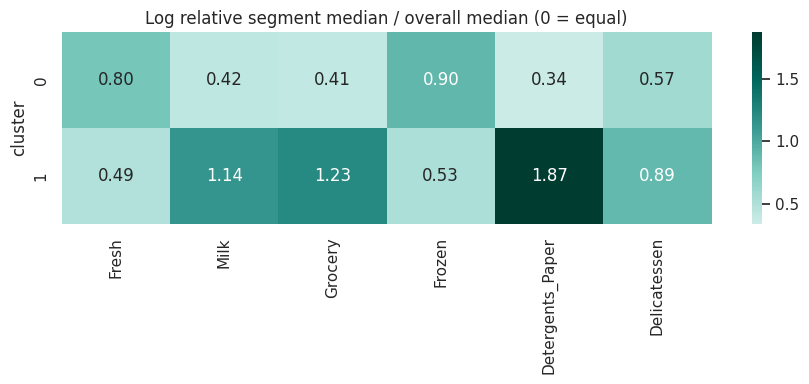

In [9]:
# Sensitivity audit: KMeans on alternative feature representations, with fixed k=2 for comparability
from sklearn.metrics import adjusted_rand_score
Xrob=RobustScaler().fit_transform(np.log1p(df[spend]))
representations={'log + standard':Xlog,'log + robust':Xrob,'raw + standard':Xraw}
ref=fits[('log_scaled','KMeans','2')]
audit=[]
for label,X in representations.items():
    km2=KMeans(n_clusters=2,n_init=20,random_state=SEED).fit_predict(X)
    audit.append({'representation':label,'ARI_vs_log_standard':adjusted_rand_score(ref,km2),
                  'silhouette':silhouette_score(X,km2),'smallest_segment':pd.Series(km2).value_counts().min()})
display(pd.DataFrame(audit).round(3))
# Repeated subsampling quantifies partition stability under observation removal.
rng=np.random.default_rng(SEED)
for rep,X in [('log + standard',Xlog),('log + robust',Xrob)]:
    original=KMeans(n_clusters=2,n_init=15,random_state=SEED).fit_predict(X)
    aris=[]
    for i in range(30):
        ix=np.sort(rng.choice(len(X),int(.8*len(X)),replace=False))
        lab=KMeans(n_clusters=2,n_init=10,random_state=SEED+i).fit_predict(X[ix])
        aris.append(adjusted_rand_score(original[ix],lab))
    print(rep,'80% subsample ARI median [10%,90%]:',np.round(np.quantile(aris,[.5,.1,.9]),3))
fig,ax=plt.subplots(figsize=(9,4))
sns.heatmap(np.log1p(profiles.div(df[spend].median().replace(0,1),axis=1)),annot=True,fmt='.2f',cmap='BrBG',center=0,ax=ax)
ax.set_title('Log relative segment median / overall median (0 = equal)');plt.tight_layout();plt.show()

## Business decision framework and defensibility

A **Fresh/Frozen-oriented** segment may justify refrigerated logistics, shorter replenishment cycles and waste-monitoring pilots; a **Grocery/Detergents-oriented** segment may justify predictable replenishment, consolidated orders and volume-based bundles. These are *hypotheses for controlled commercial trials*, not causal findings: the file contains neither margins, purchasing frequency, service costs nor satisfaction outcomes. Evaluate any rollout using gross margin after logistics costs, retention, stockouts and customer opt-outs. Do not infer customer identity or protected characteristics from `Channel` or `Region`. The observed preprocessing sensitivity limits the appropriateness of hard customer-level policies.

**References:** MacQueen (1967), *Some Methods for Classification and Analysis of Multivariate Observations*; Ward (1963), *Hierarchical Grouping to Optimize an Objective Function*; Ester et al. (1996), *A Density-Based Algorithm for Discovering Clusters in Large Spatial Databases with Noise*; Rousseeuw (1987), *Silhouettes: A Graphical Aid to the Interpretation and Validation of Cluster Analysis*; Hubert & Arabie (1985), *Comparing Partitions*.

## Confirmatory-style robustness audit: reference distributions and segment agreement
The earlier Hopkins statistic is compared with **30 independently seeded uniform null samples** in the same standardized bounding box. This is a diagnostic null, not a calibrated significance test: the bounding-box reference is sensitive to geometry and dimensionality. The analysis also compares pairwise agreement across preprocessing choices and the proportion of customers assigned consistently under 80% subsampling. All uncertainty statements refer to algorithmic resampling, not sampling uncertainty for an external population.

,observed,bounding_box_null
mean,0.796,0.498
2.5%,0.782,0.483
97.5%,0.819,0.516


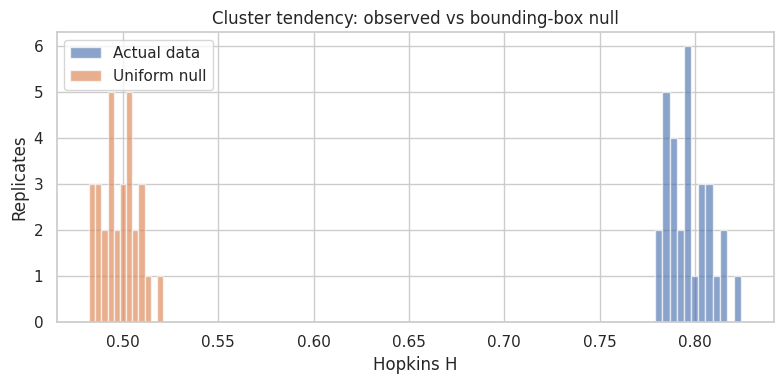

,log + standard,log + robust,raw + standard
log + standard,1.000,0.928,0.081
log + robust,0.928,1.000,0.081
raw + standard,0.081,0.081,1.000


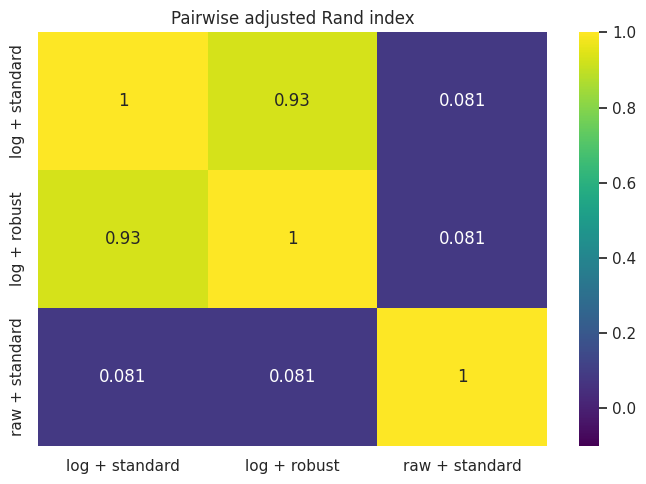

Assignment agreement over 40 80%-subsample refits:


,count,mean,median,min
cluster,,,,
0,252,0.989,1.0,0.500
1,188,0.995,1.0,0.525


Customers below 80% assignment agreement: 5


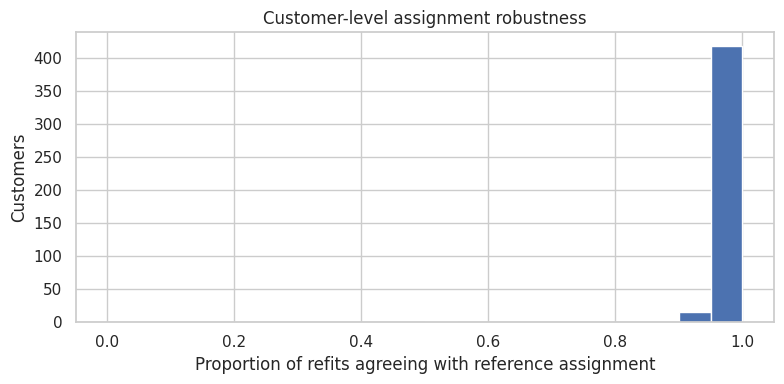

In [10]:
# Thirty independent null-reference replicates, with matched sample size and dimensionality.
rng_a=np.random.default_rng(SEED+110)
observed_h=np.array([hopkins(Xlog,SEED+300+i,m=80) for i in range(30)])
null_h=[]
for i in range(30):
    synthetic=rng_a.uniform(Xlog.min(axis=0),Xlog.max(axis=0),size=Xlog.shape)
    null_h.append(hopkins(synthetic,SEED+500+i,m=80))
null_h=np.array(null_h)
summary_h=pd.DataFrame({'observed':[observed_h.mean(),*np.quantile(observed_h,[.025,.975])],
                        'bounding_box_null':[null_h.mean(),*np.quantile(null_h,[.025,.975])]},
                        index=['mean','2.5%','97.5%'])
display(summary_h.round(3))
fig,ax=plt.subplots(figsize=(8,4));ax.hist(observed_h,bins=12,alpha=.65,label='Actual data');ax.hist(null_h,bins=12,alpha=.65,label='Uniform null');ax.set(xlabel='Hopkins H',ylabel='Replicates',title='Cluster tendency: observed vs bounding-box null');ax.legend();plt.tight_layout();plt.show()
rep_labels={name:KMeans(n_clusters=2,n_init=20,random_state=SEED).fit_predict(X) for name,X in representations.items()}
rep_names=list(rep_labels)
agreement=pd.DataFrame([[adjusted_rand_score(rep_labels[u],rep_labels[v]) for v in rep_names] for u in rep_names],index=rep_names,columns=rep_names)
display(agreement.round(3))
fig,ax=plt.subplots(figsize=(7,5));sns.heatmap(agreement,annot=True,vmin=-.1,vmax=1,cmap='viridis',ax=ax);ax.set_title('Pairwise adjusted Rand index');plt.tight_layout();plt.show()
# Compare fitted model predictions on the full dataset, not cluster labels directly (which can switch).
from scipy.optimize import linear_sum_assignment
ref_labels=rep_labels['log + standard'];ref_X=representations['log + standard'];agreement_counts=np.zeros(len(ref_X),dtype=int)
for seed_offset in range(40):
    ix=np.random.default_rng(SEED+700+seed_offset).choice(len(ref_X),int(.8*len(ref_X)),replace=False)
    candidate=KMeans(n_clusters=2,n_init=10,random_state=SEED+700+seed_offset).fit(ref_X[ix]).predict(ref_X)
    confusion=pd.crosstab(ref_labels,candidate).reindex(index=[0,1],columns=[0,1],fill_value=0).to_numpy()
    rr,cc=linear_sum_assignment(-confusion)
    mapped=np.empty_like(candidate)
    for r,c in zip(rr,cc):mapped[candidate==c]=r
    agreement_counts+=(mapped==ref_labels)
stability=agreement_counts/40
print('Assignment agreement over 40 80%-subsample refits:')
display(pd.DataFrame({'cluster':ref_labels,'agreement':stability}).groupby('cluster').agreement.agg(['count','mean','median','min']).round(3))
print('Customers below 80% assignment agreement:',int((stability<.8).sum()))
fig,ax=plt.subplots(figsize=(8,4));ax.hist(stability,bins=np.linspace(0,1,21));ax.set(xlabel='Proportion of refits agreeing with reference assignment',ylabel='Customers',title='Customer-level assignment robustness');plt.tight_layout();plt.show()

## Quantified, conditional segment actions
The table below links observed **median spending ratios** to possible merchandising decisions. Recommendations are hypotheses for a pilot, **not proven causal effects**. The spending fields represent annual monetary units, not margin, basket frequency, delivery costs, or profitability. A distributor should validate those missing variables before setting prices or service entitlements. Customers with low assignment agreement should be handled as mixed-profile accounts rather than forced into a single rigid policy.

In [11]:
segment_medians=df[spend].assign(segment=ref_labels).groupby('segment').median()
overall_medians=df[spend].median().replace(0,np.nan)
action_rows=[]
for segment in segment_medians.index:
    ratio=(segment_medians.loc[segment]/overall_medians).sort_values(ascending=False)
    action_rows.append({'segment':int(segment),'customers':int((ref_labels==segment).sum()),
                        'top_category':ratio.index[0],'top_ratio_to_overall_median':round(float(ratio.iloc[0]),2),
                        'second_category':ratio.index[1],'second_ratio':round(float(ratio.iloc[1]),2),
                        'share_low_stability':round(float((stability[ref_labels==segment]<.8).mean()),3),
                        'pilot_hypothesis':f'Test tailored {ratio.index[0]} and {ratio.index[1]} assortment; compare uptake and gross margin against control'})
actions=pd.DataFrame(action_rows);display(actions)
print('Decision rule: trial category-specific offers with a control group; stop if margin or fulfillment quality worsens.')

,segment,customers,top_category,top_ratio_to_overall_median,second_category,second_ratio,share_low_stability,pilot_hypothesis
0,0,252,Frozen,1.46,Fresh,1.22,0.016,Test tailored Frozen and Fresh assortment; com...
1,1,188,Detergents_Paper,5.51,Grocery,2.42,0.005,Test tailored Detergents_Paper and Grocery ass...


Decision rule: trial category-specific offers with a control group; stop if margin or fulfillment quality worsens.
